<a href="https://colab.research.google.com/github/emmanresu/Thesis-Keras/blob/latest%2Funstable/EDA_rice_stocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import lag_plot
from datetime import datetime

np.set_printoptions(legacy='1.25')

In [31]:
data = pd.read_csv('dataset.csv', index_col=0)
data.index = pd.to_datetime(data['date']).dt.to_period('M')
data = data.drop(columns=['date', 'month'])

### time-series visualization

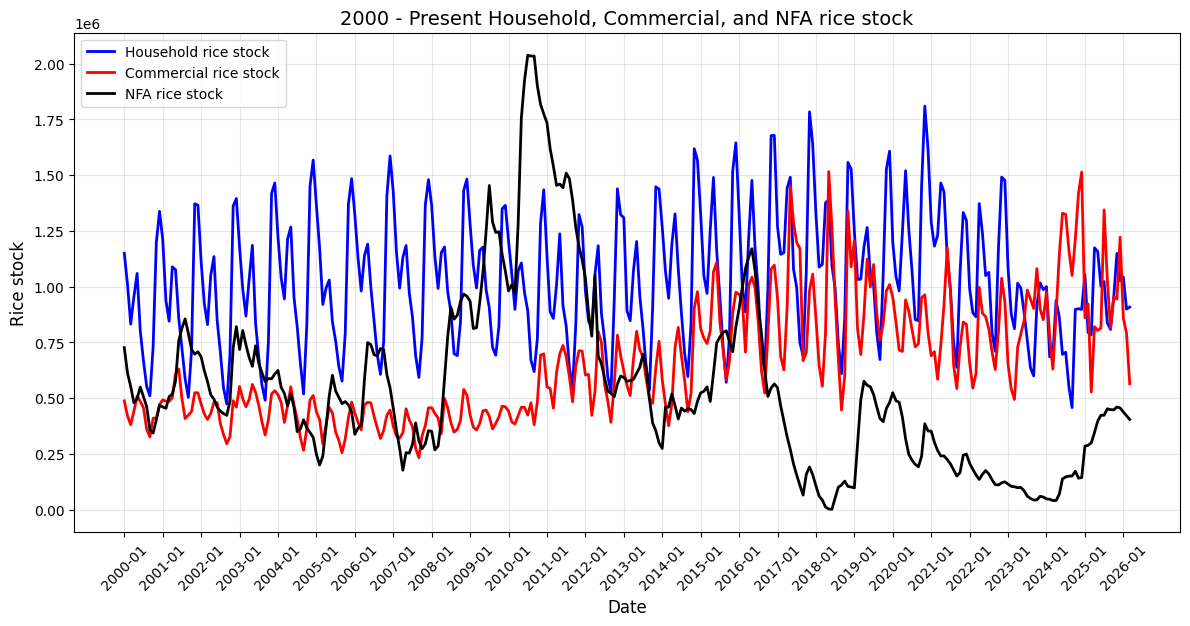

In [32]:
plt.figure(figsize=(12, 6))

data['date'] = data.index.strftime('%Y-%m')

# Adjust alpha to highlight feature
plt.plot(data['date'], data['stock_household'], label=f'Household rice stock', color='blue', linewidth=2, alpha=1)

plt.plot(data['date'], data['stock_commercial'], label=f'Commercial rice stock', color='red', linewidth=2, alpha=1)

plt.plot(data['date'], data['stock_nfa'], label=f'NFA rice stock', color='black', linewidth=2, alpha=1)

# 3. Aesthetics
plt.title('2000 - Present Household, Commercial, and NFA rice stock', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice stock', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::12], rotation=45)
data = data.drop(columns=['date'])
plt.show()

### scatter plot

In [34]:
feats = {'tot' : data['stock_total'],
         'hh' : data['stock_household'],
         'com' : data['stock_commercial'],
         'nfa' : data['stock_nfa'],
         'reg_whol' : data['regular_wholesale_price'],
         'mil_whol' : data['milled_wholesale_price'],
         'reg_ret' : data['regular_retail_price'],
         'mil_ret' : data['milled_retail_price'],
         'lm' : data['is_lean_month']}
data.columns

Index(['stock_total', 'stock_household', 'stock_commercial', 'stock_nfa',
       'regular_wholesale_price', 'milled_wholesale_price',
       'regular_retail_price', 'milled_retail_price', 'is_lean_month'],
      dtype='object')

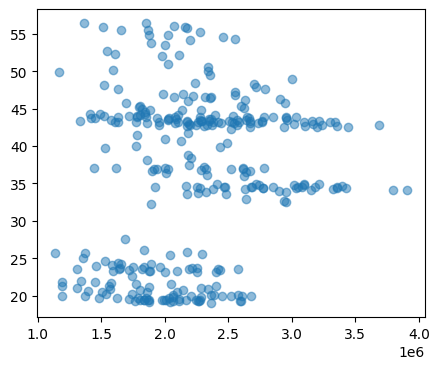

In [48]:
'''
tot -- stock total       |  reg_whol -- regular wholesale price  |   lm -- is lean month
hh --- stock household   |  mil_whol -- milled wholesale price   |
com -- stock commercial  |  reg_ret --- regular retail price     |
nfa -- stock nfa         |  mil_ret --- milled retail price      |
'''

x = feats['tot']
y = feats['mil_ret']
plt.figure(figsize=(5, 4))
plt.scatter(x, y, alpha=0.5)

### lag values scatter plot for stock_total

<Axes: xlabel='y(t)', ylabel='y(t + 24)'>

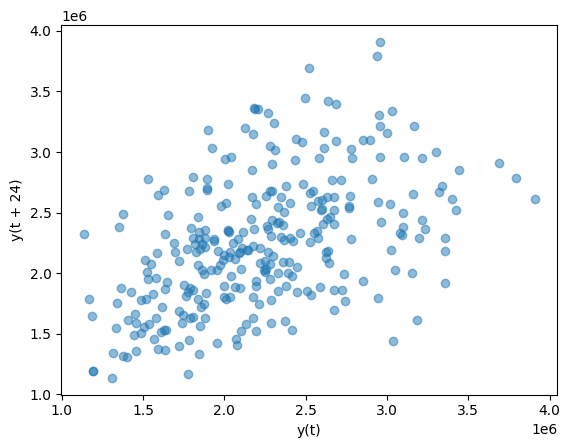

In [24]:
lag_plot(data['stock_total'], lag=24, alpha=0.5)

**stock_total** lags 1, 6, 12 are somewhat low variance (data points are tight), lag 24 show the most variance (data points are sparse)

### lag values scatter plot for features

<Axes: xlabel='y(t)', ylabel='y(t + 12)'>

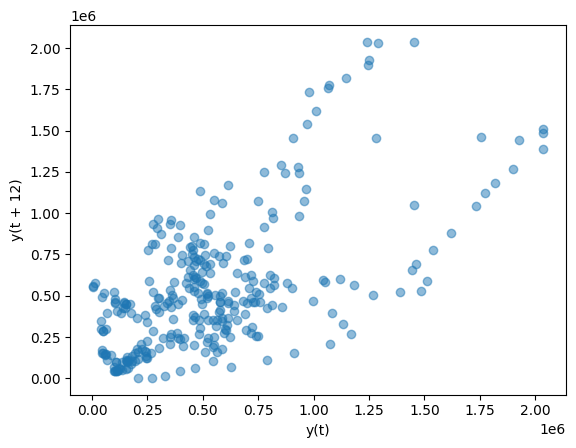

In [6]:
lag_plot(data['stock_nfa'], lag=12, alpha=0.5)

feature:

> **stock_nfa** has pretty low variance for lags 1 - 6 and somewhat sparse for lags 7 - 12






















We can use a sliding window instead of an expanding window